[![Abrir en Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Julicarrillo/EstadisticaExploracionDatos2/blob/main/2%C2%BA_PARCIAL_EED2_Carrillo_Julia.ipynb)

#SEGUNDO PARCIAL DE ESTADISTICA Y EXPLORACIÓN DE DATOS II

##Alumna: Carrillo, Julia Belén


#**Problema 1: Regresión Lineal Simple**

Objetivo: Analizar si la participación en clase es un buen predictor del rendimiento académico final.

Instrucciones: Usando el archivo proporcionado:
1. Ajustá un modelo de regresión lineal simple con NOTA como variable dependiente y PAR como variable independiente.
2. Reportá la ecuación del modelo.
3. Interpretá el coeficiente de la variable PAR.
4. Usá el modelo para predecir la nota final de un estudiante que participó 4 veces.
5. Evaluá visualmente la relación con un gráfico de dispersión + línea de regresión.

In [2]:
import pandas as pd

df = pd.read_excel('dataset_rendimiento_200 (2) (3).xlsx')

#Veo sus primeras líneas para ver que contiene el dataset
df.head()

,CB,PAR,ASIS,MOT,ESP,NOTA,APROB
0,5.6,3,15,1,0,6.64,1
1,7.3,3,18,2,0,9.46,1
2,6.7,0,15,1,0,5.57,1
3,5.3,3,24,2,1,7.10,1
4,6.0,3,17,3,0,8.17,1


In [5]:
#Vemos la forma del dataset
df.shape

(200, 7)

El dataset tiene 200 filas y 7 columnas

In [3]:
#Exploración de datos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   CB      200 non-null    float64
 1   PAR     200 non-null    int64  
 2   ASIS    200 non-null    int64  
 3   MOT     200 non-null    int64  
 4   ESP     200 non-null    int64  
 5   NOTA    200 non-null    float64
 6   APROB   200 non-null    int64  
dtypes: float64(2), int64(5)
memory usage: 11.1 KB


Acá podemos ver que el dataset aparentemente no tiene valores nulos y todas sus variables son numéricas

In [9]:
#Corroboramos que no hayan datos nulos
df.isna().sum()

,0
CB,0
PAR,0
ASIS,0
MOT,0
ESP,0
NOTA,0
APROB,0


Confirmamos que no hay datos nulos

In [14]:
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt

#Separamos las variables dependiente e independiente
X1 = df[['PAR']]
y1 = df['NOTA']

#Creamos y entrenamos el modelo
model1 = LinearRegression()
model1.fit(X1, y1)

#Obtenemos la pendiente y la ordenada al origen (intercepto)
pendiente1 = model1.coef_[0]
intercepto1 = model1.intercept_

print(f"La ecuación de la recta de regresión es: NOTA = {intercepto1:.2f} + ({pendiente1:.2f}) * PAR")

La ecuación de la recta de regresión es: NOTA = 7.58 + (0.17) * PAR


##Análisis de los coeficientes

Los valores de los coeficientes son:

Ordenada al origen = 7.58

Es decir, cuando un estudiante no participa ninguna vez en la clase (PAR = 0), obtendría una nota final de 7.58 puntos

Pendiente = 0.17, éste es el coeficiente de la variable PAR. Su valor nos dice que por cada participación adicional en clase, el modelo estima que la nota final aumenta en 0.17 puntos.

Acá podemos ver que hay una relación positiva entre la participación en clase y la nota final: cuanto más participa un alumno en clase, mayor es la nota que obtiene.



In [17]:
#Vamos a predecir la nota final de un estudiante que participó 4 veces

prediccion1 = model1.predict(np.array([[4]]))[0]

print(f"La predicción de la nota final de un estudiante que participó 4 veces es: Nota = {prediccion1:.2f}")

La predicción de la nota final de un estudiante que participó 4 veces es: Nota = 8.26


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


La predicción de la nota final de un estudiante que participó 4 veces es:

Nota = 8.26 puntos

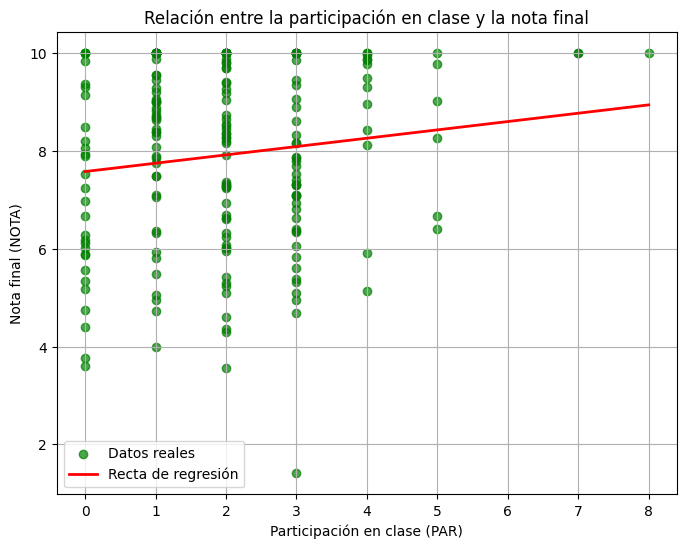

In [22]:
#Gráfico de dispersión con línea de regresión
plt.style.use('default')
plt.figure(figsize=(8, 6))
plt.scatter(X1, y1, color = 'green', alpha=0.7, label = 'Datos reales')

X_vals1 = np.linspace(X1['PAR'].min(), X1['PAR'].max(), 100)
y_vals1 = pendiente1 * X_vals1 + intercepto1

plt.plot(X_vals1, y_vals1, color='red', linestyle='-', linewidth=2, label='Recta de regresión')
plt.title('Relación entre la participación en clase y la nota final')
plt.xlabel('Participación en clase (PAR)')
plt.ylabel('Nota final (NOTA)')
plt.legend()
plt.grid(True)
plt.show()


##Análisis del gráfico

La recta de regresión tiene pendiente positiva, significa que a mayor participación en clase, la nota final aumenta ligeramente.

Los puntos verdes están bastante dispersos, significa que estudiantes con la misma cantidad de participaciones obtuvieron notas diferentes. Por ejemplo: entre quienes participaron 3 veces, vemos que hay notas cercanas a 1.5 puntos y otras cercanas a 10 puntos.

Muchos puntos estáan alejados de la recta, es decir que el modelo no logra representar con mucha presición todas las noras reales.

La relación visual parece débil, aunque exista una tendencia positiva, la participación por sí sola no parece ser un predictor muy preciso de la nota final.

Para analizar si la participación en clase es un buen predictor del rendimiento académico final tendríamos que calcular el Coeficiente de correlación de Pearson.

In [24]:
#Calculamos el coeficiente de correlación de Pearson

np.corrcoef(X1['PAR'], y1)

array([[1.        , 0.13208702],
       [0.13208702, 1.        ]])

El coeficiente de correlación de Pearson obtenido es **r = 0.132**, un valor muy cercano a 0, lo que indica que existe una relación lineal positiva, pero muy débil, entre la participación en clase y las notas finales.

Conclusión: La participación en clase, por sí sola, no parece ser un buen predictor del rendimiento académico final.

#**Problema 2: Regresión Lineal Múltiple**

Objetivo: Predecir la nota final a partir de múltiples factores académicos y personales.

Instrucciones:
1. Ajustá un modelo de regresión lineal múltiple donde:
○ Variable dependiente: NOTA
○ Variables independientes: CB, PAR, ASIS
2. Reportá los coeficientes estimados.
3. Interpretá qué variable tiene mayor peso en la predicción.
4. Verificá supuestos básicos (linealidad, normalidad de residuos, multicolinealidad).
5. Usá el modelo para predecir la nota de un estudiante con:
 CB = 6.8, PAR = 2, ASIS = 21

In [25]:
#Separamos las variables independientes y dependiente
X2 = df[['CB', 'PAR', 'ASIS']]
y2 = df['NOTA']

#Creamos y entrenamos el modelo de regresión lineal múltiple
model2 = LinearRegression()
model2.fit(X2, y2)

#Obtenemos los coeficientes de las pendientes y ordenada al origen
coeficientes2 = model2.coef_
intercepto2 = model2.intercept_

#Reportamos los coeficientes estimados
print(f"Ordenada al origen: {intercepto2:.2f}")
print(f"Coeficiente CB: {coeficientes2[0]:.2f}")
print(f"Coeficiente PAR: {coeficientes2[1]:.2f}")
print(f"Coeficiente ASIS: {coeficientes2[2]:.2f}")


Ordenada al origen: 4.00
Coeficiente CB: 0.35
Coeficiente PAR: 0.18
Coeficiente ASIS: 0.08


La ecuación del modelo re regresión lineal múltiple quedaría:

NOTA = 4.00 + 0.35 * (CB) + 0.18 * (PAR) + 0.08 * (ASIS)

##Análisis de los coeficientes:

Ordenada al origen = 4.00, cuando CB, PAR y ASIS valen cero, el modelo estimaría una nota de 4 puntos.

Coeficiente de CB = 0.35, por cada punto adicional de CB, la nota estimada aumenta 0.35 puntos, manteniendo constantes PAR y ASIS.

Coeficiente de PAR = 0.18, por cada participación en clase adicional, la nota estimada aumenta 0.18 puntos, manteniendo constantes CB y ASIS.

Coeficiente de ASIS = 0.08, por cada unidad adiscional de asistencia, la nota estimada aumenta 0.08 puntos, manteniendo constantes CB y PAR.

In [36]:
#Ahora buscamos que variables tienen mayor influencia en la predicción de la nota basándonos en el valor absoluto de cada coeficiente
most_influential_factor2 = X2.columns[np.argmax(abs(coeficientes2))]

print(f"El coeficiente que tiene mayor influencia en la predicción de la nota es: {most_influential_factor2}")


El coeficiente que tiene mayor influencia en la predicción de la nota es: CB


Al comparar los coeficientes estimados, observamos que CB tiene el mayor valor (0,35), seguido de PAR (0,18) y ASIS (0,08).

Esto indica que CB produce el mayor cambio estimado en la nota final por cada unidad adicional, manteniendo constantes las demás variables.

CB tiene mayor peso en esta predicción.

##Análisis de los supuestos básicos

1) Linealidad: verificaremos la linealidad entre cada variable independiente y la variable dependiente, y luego veremos el gráfico de residuos frente a las notas predichas para evaluar el comportamiento del modelo completo.

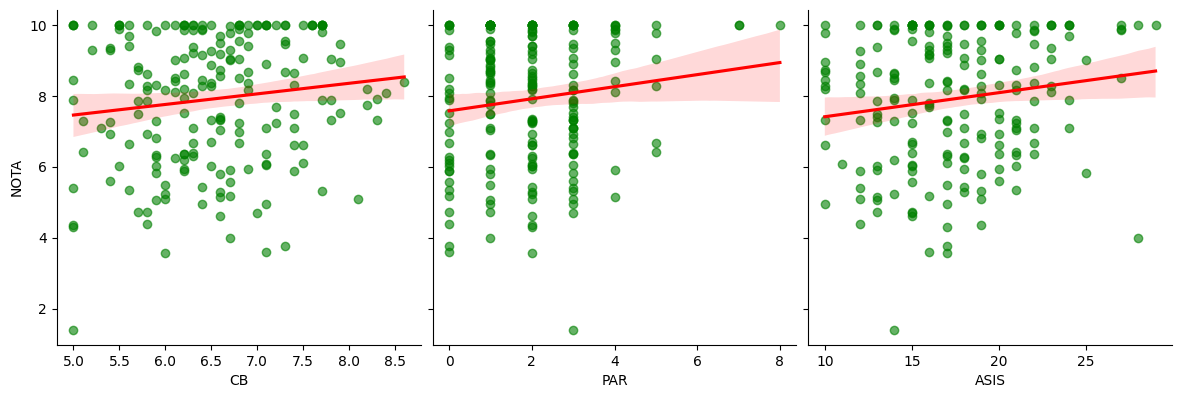

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Verificamos la linealidad entre cada variable independiente y NOTA
plt.style.use('default')

sns.pairplot(
    df,
    x_vars=['CB', 'PAR', 'ASIS'],
    y_vars='NOTA',
    kind='reg',
    height=4,
    plot_kws={
        'scatter_kws': {'color': 'green', 'alpha': 0.6},
        'line_kws': {'color': 'red'}
    }
)

plt.show()

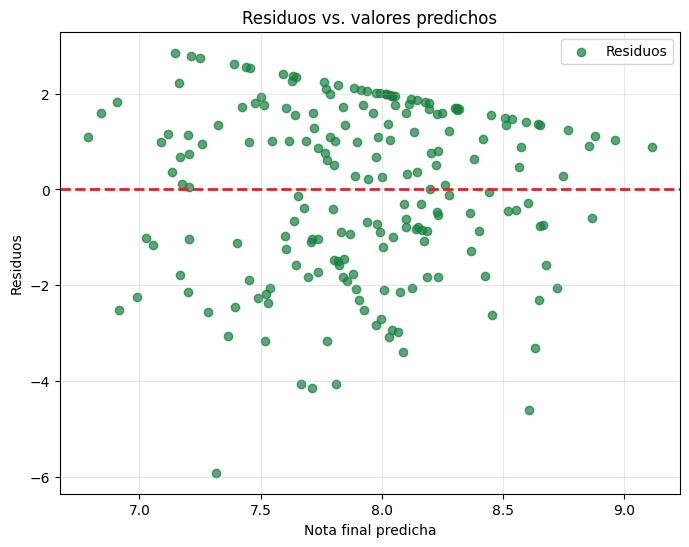

In [28]:
# Calculamos las notas predichas
y_pred2 = model2.predict(X2)

# Calculamos los residuos
residuos2 = y2 - y_pred2

# Gráfico de residuos vs valores predichos
plt.figure(figsize=(8, 6))

plt.scatter(y_pred2, residuos2, color='#15803D',
            alpha=0.7, label='Residuos')

plt.axhline(y=0, color='#DC2626',
            linestyle='--', linewidth=2)

plt.title('Residuos vs. valores predichos')
plt.xlabel('Nota final predicha')
plt.ylabel('Residuos')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

En los primeros 3 gráficos podemos ver:

CB tiene una tendencia positiva.

PAR también presenta tendencia positiva.

ASIS muestra una tendencia positiva suave.

En los 3 casos las rectas son ascendentes, pero los puntos están bastante alejados de ellas.

En el gráfico de residuos vs. valores predichos:

No vemos una curvatura evidente que indique un problema importante de linealidad. Sin embargo, la distribución de los residuos no es aleatoria, presenta algunas concentraciones y valores extremos.

Podemos decir que los gráficos son compatibles con una relación aporximadamente lineal.


2) Normalidad de residuos

Queremos ver si los errores que comete nuestro modelo siguen aproximadamente una distribución normal, para eso graficamos un histograma de los residuos.

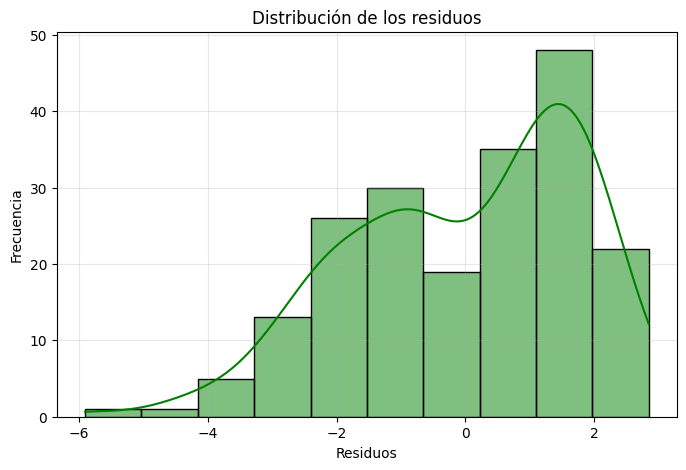

In [29]:
# Verificamos la normalidad de los residuos
plt.figure(figsize=(8, 5))

sns.histplot(residuos2, kde=True, color='green')

plt.title('Distribución de los residuos')
plt.xlabel('Residuos')
plt.ylabel('Frecuencia')
plt.grid(alpha=0.3)

plt.show()

Podemos observar que:

La distribución no presenta una forma de campana simétrica. La mayoría de los residuos se concentra en valores cercanos a cero y positivos, mientras que algunos valores negativos se extienden hasta -6.

Esto sugiere que los residuos no siguen una distribución completamente normal, por lo que el supuesto de normalidad podría no cumplirse.


3) Multicolinealidad

En nuestro modelo de regresión lineal múltiple tenemos tres variables independientes (CB, PAR y ASIS), queremos comprobar que estas variables no estén demasiado relacionadas entre sí, mediante el coeficiente de correlación de Pearson.



In [30]:
# Calculamos la matriz de correlación entre las variables independientes
correlacion2 = X2.corr()

# Mostramos la matriz con 2 decimales
correlacion2.round(2)

,CB,PAR,ASIS
CB,1.00,-0.03,-0.1
PAR,-0.03,1.00,-0.0
ASIS,-0.10,-0.00,1.0


Análisis de la matriz de correlación

CB y PAR : -0.03 = Relación negativa y muy débil.

CB y ASIS: -0.1 = Relación negativa y muy débil.

PAR y ASIS: -0.00 = Relación nula

No se observan relaciones lineales fuertes entre las variables independientes, lo que indica que no hay señales importantes de multicolinealidad entre pares de variables.

Ahora queremos predecir la nota de un estudiante con CB=6.8, PAR=2, ASIS=21.

Recordemos que la ecuación del modelo de regresión lineal múltiple es:

NOTA = 4.00 + 0.35 * (CB) + 0.18 * (PAR) + 0.08 * (ASIS)

In [31]:
prediccion2 = model2.predict(np.array([[6.8, 2, 21]]))

print(f"La nota predicha es: {prediccion2[0]:.2f}")


La nota predicha es: 8.29


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


 Para un estudiante con: CB = 6.8, PAR = 2, ASIS = 21, el modelo predice una nota de 8.29 puntos.

#**Problema 3: Regresión Logística**
Objetivo: Predecir la probabilidad de aprobar la asignatura en función de variables personales y académicas.
Instrucciones:
1. Ajustá un modelo de regresión logística donde:
Variable dependiente: APROB (1 = aprobó, 0 = no aprobó)
Variables independientes: CB, PAR, MOT, ESP
2. Reportá los coeficientes logísticos y su significancia.
3. Calculá la probabilidad de aprobar para un estudiante con:
CB = 6.0, PAR = 3, MOT = 3, ESP = 1
4. Interpretá qué variable tiene mayor influencia en el resultado.

In [32]:
#Importamos la librería para regresión logística
from sklearn.linear_model import LogisticRegression

#Separamos las variables independientes y dependiente
X3 = df[['CB', 'PAR', 'MOT', 'ESP']]
y3 = df['APROB']

#Creamos y entrenamos el modelo
model3 = LogisticRegression()
model3.fit(X3, y3)

#Obtenemos los coeficientes del modelo
coeficientes3 = model3.coef_[0]
intercepto3 = model3.intercept_[0]

print(f"Intercepto: {intercepto3:.2f}")
print(f"Coeficiente CB: {coeficientes3[0]:.2f}")
print(f"Coeficiente PAR: {coeficientes3[1]:.2f}")
print(f"Coeficiente MOT: {coeficientes3[2]:.2f}")
print(f"Coeficiente ESP: {coeficientes3[3]:.2f}")

Intercepto: -2.08
Coeficiente CB: 0.58
Coeficiente PAR: 0.32
Coeficiente MOT: 0.08
Coeficiente ESP: 0.49


Análisis de los coeficientes:

Intercepto = -2.08, valor inicial del modelo cuando todas las variables valen cero.

Coeficiente de CB = 0.58: Si CB aumenta en una unidad, aumentan las chances de aprobar, manteniendo las demás variables constantes.

Coeficiente de PAR = 0.32: Si aumenta la participación, también aumentan las chances de aprobar, manteniendo las demás variables constantes.

Coeficiente de MOT = 0.08: tiene un coeficiente positivo pero pequeño, también aumentan las chances de aprobar levemente, manteniendo las demás variables constantes.

Coeficiente de ESP = 0.49: Si ESP aumenta en una unidad, también aumentan las chances de aprobar, manteniendo las demás variables constantes.

Ahora vamos a calcular la probabilidad de aprobar para un estudiante con:

CB = 6.0, PAR = 3, MOT = 3, ESP = 1.



In [35]:
#Probabilidad de aprobar
prediccion3 = model3.predict_proba(np.array([[6, 3, 3, 1]]))

print(np.round(prediccion3, 2))

[[0.04 0.96]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


Análisis del resultado:

Nuestra predicción nos devuelve el siguiente array: [[0.04 0.96]]

Esto significa 4% de posibilidades de no aprobar y 96% de porbabilidades de aprobar.

Por lo tanto, se estima que este estudiante tiene una probabilidad muy alta de aprobar la materia.

In [37]:
#Buscamos el coeficiente que tiene mayor influencia en la predicción basándonos en el valor absoluto

most_influential_factor3 = X3.columns[np.argmax(abs(coeficientes3))]

print(f"El coeficiente que tiene mayor influencia en la predicción de la nota es: {most_influential_factor3}")

El coeficiente que tiene mayor influencia en la predicción de la nota es: CB


La variable CB presenta el coeficiente logístico de mayor magnitud (0,58), seguida de ESP (0,49), PAR (0,32) y MOT (0,08).

Esto indica que CB tiene la mayor influencia sobre las chances de aprobar por cada unidad adicional, manteniendo constantes las demás variables.